In [19]:
import numpy as np
import matplotlib.pyplot as plt
from time import perf_counter
from src.metamaterial.physics.coupling.full_retarded_old import L_parallel as L_par_full
from src.metamaterial.physics.coupling.full_retarded_old import L_orthogonal as L_ort_full
from src.metamaterial.physics.coupling.full_retarded import L_parallel as L_par_sum
from src.metamaterial.physics.coupling.full_retarded import L_orthogonal as L_ort_sum
from src.metamaterial.physics.coupling.approx_retarded import L_parallel as L_par_rec
from src.metamaterial.physics.coupling.approx_retarded import L_orthogonal as L_ort_rec

## error and speedup

In [2]:
r1 = 4.935 * 10 ** -3
r2=r1
dx = np.linspace(3*r1, 50*r1, 100)
dy = np.zeros_like(dx)
dz = dx
omega = 2*np.pi*1e7

In [3]:
t0 = time.time()
L_par_full_values = np.asarray([L_par_full(omega, dx[i], dy[i], dz[i], r1,r2) for i in range(len(dx))])
t1 = time.time()
L_par_sum_values = np.asarray([L_par_sum(omega, dx[i], dy[i], dz[i], r1,r2) for i in range(len(dx))])
t2 = time.time()
L_ort_full_values = np.asarray([L_ort_full(omega, dx[i], dy[i], dz[i], r1,r2) for i in range(len(dx))])
t3 = time.time()
L_ort_sum_values = np.asarray([L_ort_sum(omega, dx[i], dy[i], dz[i], r1,r2) for i in range(len(dx))])
t4 = time.time()

In [4]:
print(f"Speedup parallel: {(t1 - t0) / (t2 - t1)}")
print(f"Speedup orthogonal: {(t3 - t2) / (t4 - t3)}")

Speedup parallel: 18.58900984049947
Speedup orthogonal: 20.26267268906451


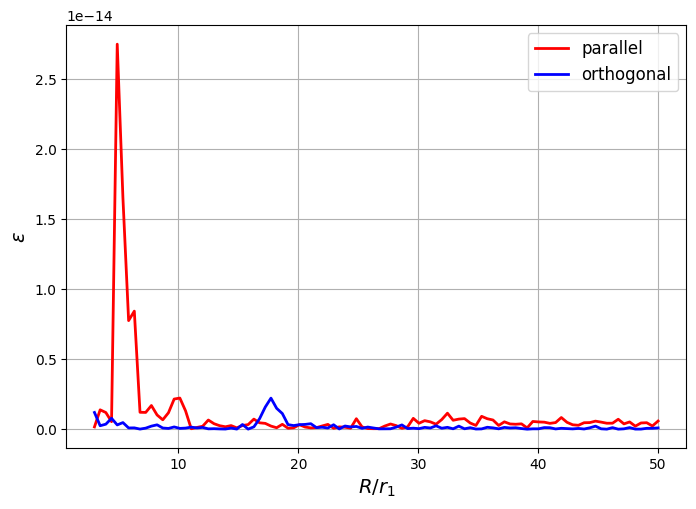

In [16]:
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.plot(dx/r1, np.abs((L_par_full_values-L_par_sum_values)/(L_par_full_values+1e-5)), label='parallel', color='red', linewidth=2)
ax.plot(dx/r1, np.abs((L_ort_full_values-L_ort_sum_values)/(L_ort_full_values+1e-5)), label='orthogonal', color='blue', linewidth=2)
ax.set_xlabel('$R/r_1$', fontsize=14)
ax.set_ylabel(r'$\varepsilon$', fontsize=14)
ax.legend(fontsize=12)
plt.grid()
plt.show()

## Time estimation

In [21]:
r1 = 4.935 * 10 ** -3
r2=r1
dx = np.linspace(3*r1, 50*r1, 100)
dy = np.linspace(3*r1, 50*r1, 100)
dz = np.ones_like(dx)*r1
omega = 2*np.pi*1e7
repeats = 4

In [25]:
times_full = np.empty((2, repeats))
times_sum = np.empty((2, repeats))
times_rec = np.empty((2, repeats))

for rep in range(repeats):
    t0 = perf_counter()
    L_par_full_values = np.asarray([L_par_full(omega, dx[i], dy[i], dz[i], r1,r2) for i in range(len(dx))])
    times_full[0, rep] = perf_counter() - t0
    t1 = perf_counter()
    L_par_sum_values = np.asarray([L_par_sum(omega, dx[i], dy[i], dz[i], r1,r2) for i in range(len(dx))])
    times_sum[0, rep] = perf_counter() - t1
    t2 = perf_counter()
    L_par_rec_values = np.asarray([L_par_rec(omega, dx[i], dy[i], dz[i], r1,r2) for i in range(len(dx))])
    times_rec[0, rep] = perf_counter() - t2
    t3 = perf_counter()
    L_ort_full_values = np.asarray([L_ort_full(omega, dx[i], dy[i], dz[i], r1,r2) for i in range(len(dx))])
    times_full[1, rep] = perf_counter() - t3
    t4 = perf_counter()
    L_ort_sum_values = np.asarray([L_ort_sum(omega, dx[i], dy[i], dz[i], r1,r2) for i in range(len(dx))])
    times_sum[1, rep] = perf_counter() - t4
    t5 = perf_counter()
    L_ort_rec_values = np.asarray([L_ort_rec(omega, dx[i], dy[i], dz[i], r1,r2) for i in range(len(dx))])
    times_rec[1, rep] = perf_counter() - t5



print(f'Parallel full retarded time (scipy.integrate): {np.min(times_full[0, :]):.6f} seconds')
print(f'Parallel full retarded time (trapezoidal rule): {np.min(times_sum[0, :]):.6f} seconds')
print(f'Parallel approx retarded time: {np.mean(times_rec[0, :]):.6f} seconds')

print(f'Orthogonal full retarded time (scipy.integrate): {np.min(times_full[1, :]):.6f} seconds')
print(f'Orthogonal full retarded time (trapezoidal rule): {np.min(times_sum[1, :]):.6f} seconds')
print(f'Orthogonal approx retarded time: {np.mean(times_rec[1, :]):.6f} seconds')

Parallel full retarded time (scipy.integrate): 5.759671 seconds
Parallel full retarded time (trapezoidal rule): 0.257710 seconds
Parallel approx retarded time: 0.028851 seconds
Orthogonal full retarded time (scipy.integrate): 4.443754 seconds
Orthogonal full retarded time (trapezoidal rule): 0.267093 seconds
Orthogonal approx retarded time: 0.172578 seconds
